<h3 style="text-align:center">ESERCITAZIONE FINALE<br>IL CASO DI TOYSGROUP IN PYTHON</h3>

### TASK 1 PYTHON DI BASE SUI DATI FORNITI ###

## Task 1 - Punto 1: lettura dei dati
Leggo products.csv e sales.json come liste di dizionari,
costruisco il dizionario regions {RegionID: (State, SalesRegion)} e il set delle categorie.

In [1]:
import pandas as pd
## Leggo i file e li trasformo in liste di dizzionari
products = pd.read_csv("products.csv").to_dict(orient="records")
vendite = pd.read_json("sales.json").to_dict(orient="records")

## Costruisco il dizzionario delle regioni
regions_df = pd.read_excel("regions.xlsx")
regions = {}
for riga in regions_df.to_dict(orient="records"):
    regions[riga["RegionID"]] = (riga["State"], riga["SalesRegion"])

## Costruisco il set delle categorie
categorie = set()
for p in products:
    categorie.add(p["Category"])

## Stampo i risultati

print(len(products))
print(len(vendite))
print(products)
print(regions)
print(categorie)
    

12
2000
[{'ProductID': 1, 'ProductName': 'Bici Junior', 'Category': 'Outdoor', 'ListPrice': 129.0}, {'ProductID': 2, 'ProductName': 'Bici BMX', 'Category': 'Outdoor', 'ListPrice': 189.0}, {'ProductID': 3, 'ProductName': 'Monopattino', 'Category': 'Outdoor', 'ListPrice': 79.0}, {'ProductID': 4, 'ProductName': 'Pallone Calcio', 'Category': 'Outdoor', 'ListPrice': 19.9}, {'ProductID': 5, 'ProductName': 'Racchette Beach', 'Category': 'Outdoor', 'ListPrice': 14.5}, {'ProductID': 6, 'ProductName': 'Puzzle 1000', 'Category': 'Giochi da tavolo', 'ListPrice': 17.9}, {'ProductID': 7, 'ProductName': "Gioco dell'Oca", 'Category': 'Giochi da tavolo', 'ListPrice': 12.5}, {'ProductID': 8, 'ProductName': 'Scacchi Legno', 'Category': 'Giochi da tavolo', 'ListPrice': 34.0}, {'ProductID': 9, 'ProductName': 'Costruzioni 500', 'Category': 'Giocattoli', 'ListPrice': 39.9}, {'ProductID': 10, 'ProductName': 'Bambola Classica', 'Category': 'Giocattoli', 'ListPrice': 24.9}, {'ProductID': 11, 'ProductName': 'Rob

## Task 1-Punto 2: Fascia di prezzo
con una list comprehension e un costrutto if/elif/else assegno a ogni
prodotto la fascia di prezzo: Bassa sotto 20 €, Media fino a 60 €, Alta oltre.

In [2]:
def fascia_prezzo(prezzo):
    if prezzo < 20:
        return "Bassa"
    elif prezzo <= 60:
        return "Media"
    else:
        return "Alta"


prodotti_con_fascia = [
    {"ProductName":p["ProductName"],"ListPrice": p["ListPrice"], "Fascia": fascia_prezzo(p["ListPrice"])}
    for p in products
]

for p in prodotti_con_fascia:
    print(p)

{'ProductName': 'Bici Junior', 'ListPrice': 129.0, 'Fascia': 'Alta'}
{'ProductName': 'Bici BMX', 'ListPrice': 189.0, 'Fascia': 'Alta'}
{'ProductName': 'Monopattino', 'ListPrice': 79.0, 'Fascia': 'Alta'}
{'ProductName': 'Pallone Calcio', 'ListPrice': 19.9, 'Fascia': 'Bassa'}
{'ProductName': 'Racchette Beach', 'ListPrice': 14.5, 'Fascia': 'Bassa'}
{'ProductName': 'Puzzle 1000', 'ListPrice': 17.9, 'Fascia': 'Bassa'}
{'ProductName': "Gioco dell'Oca", 'ListPrice': 12.5, 'Fascia': 'Bassa'}
{'ProductName': 'Scacchi Legno', 'ListPrice': 34.0, 'Fascia': 'Media'}
{'ProductName': 'Costruzioni 500', 'ListPrice': 39.9, 'Fascia': 'Media'}
{'ProductName': 'Bambola Classica', 'ListPrice': 24.9, 'Fascia': 'Media'}
{'ProductName': 'Robot RC', 'ListPrice': 89.0, 'Fascia': 'Alta'}
{'ProductName': 'Macchinina RC', 'ListPrice': 59.0, 'Fascia': 'Media'}


## Task 1 - Punto 3: fatturato per categoria
Scrivo la funzione fatturato_categoria(vendite, prodotti, categoria) che, con un ciclo for, somma SalesAmount della categoria, salta i valori mancanti (NaN) e restituisce il totale con return.

Risultati: Giocattoli 174.832,00 €, Outdoor 331.998,40 €, Giochi da tavolo 53.245,10 €.

In [3]:
import math

def fatturato_categoria(vendite, prodotti, categoria):
    # rubrica di appoggio: ProductID -> Category
    categoria_di = {}
    for p in prodotti:
        categoria_di[p["ProductID"]] = p["Category"]

    totale = 0
    for v in vendite:
        importo = v["SalesAmount"]
        if math.isnan(importo):
            continue
        if categoria_di[v["ProductID"]] == categoria:
            totale += importo
    return totale

for c in categorie:
    print(c, round(fatturato_categoria(vendite, products, c), 2))

Giocattoli 174832.0
Outdoor 331998.4
Giochi da tavolo 53245.1


## Task 1 - Punto 4: ciclo while e primi 5 elementi
Con un ciclo while conto le transazioni necessarie a superare 10.000 € di fatturato cumulato e mostro le prime cinque transazioni con vendite[:5]. Transazioni necessarie: 52.

In [4]:
import math
soglia = 10000
cumulato = 0
contate = 0
i = 0

while cumulato <= soglia and i < len(vendite):
    importo = vendite [i]["SalesAmount"]
    if not math.isnan(importo):
        cumulato += importo
        contate += 1
    i += 1
print("Transazioni necessarie:",contate)
print("Righe scorse (comprese quelle senza importo):",i)
print("Fatturato cumulato:",round(cumulato,2))

for v in vendite [:5]:
    print(v)

Transazioni necessarie: 52
Righe scorse (comprese quelle senza importo): 56
Fatturato cumulato: 10164.8
{'SalesID': 1194, 'ProductID': 6, 'RegionID': 7, 'ResellerID': 283, 'SalesDate': '2023-01-01', 'Quantity': 4.0, 'SalesAmount': 71.6}
{'SalesID': 859, 'ProductID': 6, 'RegionID': 8, 'ResellerID': 28, 'SalesDate': '2023-01-02', 'Quantity': 7.0, 'SalesAmount': nan}
{'SalesID': 1747, 'ProductID': 12, 'RegionID': 3, 'ResellerID': 281, 'SalesDate': '2023-01-02', 'Quantity': 2.0, 'SalesAmount': 118.0}
{'SalesID': 279, 'ProductID': 3, 'RegionID': 7, 'ResellerID': 128, 'SalesDate': '2023-01-02', 'Quantity': 3.0, 'SalesAmount': nan}
{'SalesID': 1470, 'ProductID': 1, 'RegionID': 6, 'ResellerID': 137, 'SalesDate': '2023-01-04', 'Quantity': 4.0, 'SalesAmount': nan}


### DEFINIZIONI

## LISTA
È una sequenza ordinata e mutabile di elementi, accessibile per indice. Può contenere duplicati e si scrive con [].

## TUPLA
È una sequenza ordinata e immutabile di elementi, accessibile per indice. Può contenere duplicati e si scrive con ().

## SET
È una collezione non ordinata e mutabile di elementi unici, non accessibile per indice. Non contiene duplicati e si scrive con {} (il set vuoto si scrive set()).

## DIZIONARIO
È una collezione mutabile di coppie chiave → valore, accessibile per chiave, che mantiene l'ordine di inserimento. Le chiavi devono essere uniche e immutabili, i valori possono essere duplicati. Si scrive con {}.


### TASK 2 · LETTURA E ISPEZIONE DEI DATI ###

## Task 2 - Punto 1: lettura e ispezione dei dati
Leggo i quattro file in DataFrame e riporto per ciascuno dimensioni, struttura, prime e ultime righe.

In [5]:
import pandas as pd

df_products = pd.read_csv("products.csv")
df_regions = pd.read_excel("regions.xlsx")
df_sales = pd.read_json("sales.json")
df_resellers = pd.read_csv("resellers.csv")

tabelle = {
    "products": df_products,
    "regions": df_regions,
    "sales": df_sales,
    "resellers": df_resellers,
}
for nome, df in tabelle.items():
    print("=====", nome, "=====")
    print("Righe e colonne:", df.shape)
    df.info()
    display(df.head())
    display(df.tail())

===== products =====
Righe e colonne: (12, 4)
<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ProductID    12 non-null     int64  
 1   ProductName  12 non-null     str    
 2   Category     12 non-null     str    
 3   ListPrice    12 non-null     float64
dtypes: float64(1), int64(1), str(2)
memory usage: 788.0 bytes


,ProductID,ProductName,Category,ListPrice
0,1,Bici Junior,Outdoor,129.0
1,2,Bici BMX,Outdoor,189.0
2,3,Monopattino,Outdoor,79.0
3,4,Pallone Calcio,Outdoor,19.9
4,5,Racchette Beach,Outdoor,14.5


,ProductID,ProductName,Category,ListPrice
7,8,Scacchi Legno,Giochi da tavolo,34.0
8,9,Costruzioni 500,Giocattoli,39.9
9,10,Bambola Classica,Giocattoli,24.9
10,11,Robot RC,Giocattoli,89.0
11,12,Macchinina RC,Giocattoli,59.0


===== regions =====
Righe e colonne: (9, 3)
<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   RegionID     9 non-null      int64
 1   State        9 non-null      str  
 2   SalesRegion  9 non-null      str  
dtypes: int64(1), str(2)
memory usage: 515.0 bytes


,RegionID,State,SalesRegion
0,1,Italia,Sud Europa
1,2,Francia,Sud Europa
2,3,Spagna,Sud Europa
3,4,Germania,Centro Europa
4,5,Austria,Centro Europa


...

,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
0,1194,6,7,283,2023-01-01,4.0,71.6
1,859,6,8,28,2023-01-02,7.0,NaN
2,1747,12,3,281,2023-01-02,2.0,118.0
3,279,3,7,128,2023-01-02,3.0,NaN
4,1470,1,6,137,2023-01-04,4.0,NaN


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
1995,326,3,1,280,2025-12-27,4.0,316.0
1996,394,7,2,256,2025-12-29,5.0,62.5
1997,196,4,8,50,2025-12-29,5.0,99.5
1998,878,4,4,27,2025-12-30,8.0,159.2
1999,1278,9,5,57,2025-12-30,9.0,359.1


===== resellers =====
Righe e colonne: (300, 7)
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ResellerID          300 non-null    int64  
 1   RegionID            300 non-null    int64  
 2   Ordini12m           300 non-null    int64  
 3   GiorniUltimoOrdine  300 non-null    int64  
 4   ScontoMedio         300 non-null    float64
 5   Reclami             300 non-null    int64  
 6   Churn               300 non-null    int64  
dtypes: float64(1), int64(6)
memory usage: 16.5 KB


,ResellerID,RegionID,Ordini12m,GiorniUltimoOrdine,ScontoMedio,Reclami,Churn
0,1,1,14,65,0.131,1,0
1,2,7,9,149,0.117,1,0
2,3,6,21,1,0.065,2,0
3,4,4,18,162,0.011,1,1
4,5,4,22,98,0.120,0,0


,ResellerID,RegionID,Ordini12m,GiorniUltimoOrdine,ScontoMedio,Reclami,Churn
295,296,5,18,145,0.218,1,0
296,297,8,17,104,0.048,0,0
297,298,4,16,141,0.055,2,0
298,299,3,13,113,0.164,0,0
299,300,1,12,116,0.072,0,0


## Task 2 - Punto 2: statistiche descrittive e prezzo unitario
Con .describe() ho trovato minimo, massimo e media di Quantity e SalesAmount. Poi ho convertito le due colonne in array NumPy e ho calcolato con un'operazione vettoriale il prezzo unitario di ogni vendita (SalesAmount / Quantity), senza modificare il DataFrame.

| | Minimo | Massimo | Media |
|---|---|---|---|
| Quantity | 1 | 14 | 4,97 |
| SalesAmount (€) | 12,50 | 2.457,00 | 294,78 |

I prezzi unitari calcolati (12,5, 14,5, 17,9, 19,9, ...) coincidono con i prezzi di listino, quindi i dati sono coerenti. Dove manca la quantità o l'importo il risultato è NaN (198 valori).

In [6]:
import numpy as np
#statistiche descrittive delle due colonne
display(df_sales[["Quantity","SalesAmount"]].describe())

#conversione in array NumPy
quantita = df_sales["Quantity"].to_numpy()
importi = df_sales["SalesAmount"].to_numpy()

#operazione vettoriale : prezzo unitario di ogni vendita
prezzo_unitario = importi / quantita

print(prezzo_unitario[:10])
print("Valori mancanti nel risultato:", np.isnan(prezzo_unitario).sum())

,Quantity,SalesAmount
count,1900.000000,1900.000000
mean,4.966316,294.776579
std,2.206535,305.261212
min,1.000000,12.500000
25%,3.000000,89.000000
50%,5.000000,177.000000
75%,6.000000,387.000000
max,14.000000,2457.000000


[17.9  nan 59.   nan  nan 12.5 79.  79.  12.5  nan]
Valori mancanti nel risultato: 198


## Task 2 - Punto 3: selezione con .loc[] e .iloc[]
Con .loc[] e una maschera booleana ho selezionato i prodotti Outdoor con ListPrice superiore a 30 €: sono 3 (Bici Junior, Bici BMX e Monopattino). Con .iloc[] ho preso le righe da 10 a 19 e le prime tre colonne di sales, ottenendo 10 righe e 3 colonne. Nessun DataFrame è stato modificato.

In [7]:
# .loc[] con maschera booleana: prodotti Outdoor con prezzo > 30 €
maschera = (df_products["Category"] == "Outdoor") & (df_products["ListPrice"] > 30)
prodotti_selezionati = df_products.loc[maschera, ["ProductName", "Category", "ListPrice"]]
display(prodotti_selezionati)

# .iloc[]: righe da 10 a 19 e prime tre colonne di sales
selezione_sales = df_sales.iloc[10:20, :3]
display(selezione_sales)
print("Dimensioni della selezione:", selezione_sales.shape)

,ProductName,Category,ListPrice
0,Bici Junior,Outdoor,129.0
1,Bici BMX,Outdoor,189.0
2,Monopattino,Outdoor,79.0


,SalesID,ProductID,RegionID
10,218,1,8
11,1136,1,9
12,1326,3,4
13,1063,9,7
14,1606,10,8
15,1283,12,1
16,98,3,4
17,156,6,8
18,1642,12,5
19,1644,4,7


Dimensioni della selezione: (10, 3)


### Definizione: Series e DataFrame , .loc[] e .iloc[]

## Una Series 
è una singola colonna di dati con il suo indice (per esempio df["ListPrice"]). 
## Un DataFrame 
è una tabella formata da più colonne che condividono lo stesso indice (per esempio df_products): si può vedere come un insieme di Series affiancate.

## .loc[] 
seleziona righe e colonne per etichetta (nome della colonna o valore dell'indice) o con    una maschera booleana, e l'estremo finale di un intervallo è incluso.
## .iloc[] 
seleziona per posizione intera, contando da 0, e l'estremo finale è escluso.

## TASK 3A DATI MANCANTI, FILTRI E ORDINAMENTO ##


## Task 3a - Punto 1: valori mancanti nelle vendite
Creo una copia del DataFrame delle vendite (df_sales_clean) e conto i valori mancanti per colonna, 
calcolandone anche la percentuale sul totale delle righe.
Quantity e SalesAmount hanno 100 valori mancanti ciascuno, pari al 5%.


In [8]:
df_sales_clean = df_sales.copy()

nan_prima = pd.DataFrame({
    "NaN": df_sales_clean.isna().sum(),
    "Percentuale (%)": (df_sales_clean.isna().sum() / len(df_sales_clean) * 100).round(2),
})
display(nan_prima)

,NaN,Percentuale (%)
SalesID,0,0.0
ProductID,0,0.0
RegionID,0,0.0
ResellerID,0,0.0
SalesDate,0,0.0
Quantity,100,5.0
SalesAmount,100,5.0


## Task 3a - Punto 2: imputazione e rimozione dei valori mancanti
Imputo Quantity con la mediana della colonna, calcolata sui valori presenti prima del fillna(). 
Elimino con dropna() le righe con SalesAmount mancante, perché l'importo è il dato da analizzare e inventarlo falserebbe il fatturato.

Righe rimosse: 100 (da 2000 a 1900).

In [9]:
righe_prima = len(df_sales_clean)

# 1) Imputazione di Quantity con la mediana (calcolata sui valori presenti)
mediana_quantity = df_sales_clean["Quantity"].median()
df_sales_clean["Quantity"] = df_sales_clean["Quantity"].fillna(mediana_quantity)

# 2) Eliminazione delle righe con SalesAmount mancante
df_sales_clean = df_sales_clean.dropna(subset=["SalesAmount"])

righe_rimosse = righe_prima - len(df_sales_clean)
print("Mediana di Quantity:", mediana_quantity)
print("Righe rimosse:", righe_rimosse)
print("Righe rimaste:", len(df_sales_clean))

# Tabella dei NaN prima e dopo il trattamento
nan_dopo = df_sales_clean.isna().sum()
confronto = pd.DataFrame({"NaN prima": nan_prima["NaN"], "NaN dopo": nan_dopo})
display(confronto)

Mediana di Quantity: 5.0
Righe rimosse: 100
Righe rimaste: 1900


,NaN prima,NaN dopo
SalesID,0,0
ProductID,0,0
RegionID,0,0
ResellerID,0,0
SalesDate,0,0
Quantity,100,0
SalesAmount,100,0


## Task 3a - Punto 3: transazioni sopra il 90° percentile
Con quantile(0.9) calcolo la soglia del 90° percentile di SalesAmount e con query() estraggo le transazioni
con importo superiore. Le ordino per data crescente e, a parità di data, per importo decrescente. Verifica con head(10).

Soglia del 90° percentile: 756,00 €. 
Transazioni sopra la soglia: 162.

In [10]:
soglia_90 = df_sales_clean["SalesAmount"].quantile(0.9)

top_vendite = df_sales_clean.query("SalesAmount > @soglia_90")
top_vendite = top_vendite.sort_values(by=["SalesDate", "SalesAmount"], ascending=[True, False])

print("Soglia 90° percentile:", soglia_90)
print("Transazioni sopra la soglia:", len(top_vendite))
display(top_vendite.head(10))

Soglia 90° percentile: 756.0
Transazioni sopra la soglia: 162


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
32,1045,2,4,82,2023-01-16,6.0,1134.0
49,1872,2,7,204,2023-01-25,5.0,945.0
52,1639,1,3,299,2023-01-27,9.0,1161.0
102,296,2,9,202,2023-02-25,5.0,945.0
118,1462,2,2,224,2023-03-03,5.0,945.0
121,1221,1,8,149,2023-03-05,8.0,1032.0
123,1753,2,8,151,2023-03-05,5.0,945.0
168,283,2,2,100,2023-03-30,11.0,2079.0
217,1679,1,4,22,2023-04-27,5.0,774.0
221,832,2,4,82,2023-04-28,6.0,1134.0


### Definizione: imputazione dei dati mancanti

L'imputazione consiste nel sostituire i valori mancanti con un valore stimato, per non perdere le righe che li contengono.

- **Media:** semplice, adatta a distribuzioni simmetriche e senza valori estremi, ma molto influenzata dagli outlier.
- **Mediana:** il valore centrale dei dati ordinati, robusta agli outlier e preferibile quando la distribuzione è asimmetrica (è la scelta fatta per Quantity).
- **Eliminazione della riga:** adatta quando i mancanti sono pochi o riguardano la variabile da analizzare, perché non inventa dati (è la scelta fatta per SalesAmount), ma riduce il campione e può introdurre distorsioni se i dati non mancano a caso.

**Effetto sulla distribuzione:** imputare con un unico valore concentra molte osservazioni su quel punto, quindi la distribuzione diventa più "appuntita" e la variabilità diminuisce. Eliminare le righe mantiene la forma dei dati, ma riduce il numero di osservazioni.

### TASK 3B · AGGREGAZIONI E COMBINAZIONI DEI DATAFRAME

## Task 3b - Punto 1: unione di sales con products e regions
Unisco le vendite pulite (df_sales_clean) con products su ProductID e con regions su RegionID, con how="left" per non perdere nessuna vendita. 
Verifico che il numero di righe resti quello di sales e che non ci siano valori mancanti introdotti dal merge.
Righe di sales 1900 , righe dopo il merge 1900, valori mancanti introdotti 0

In [11]:
df_full=pd.merge(df_sales_clean, df_products, on="ProductID", how="left")
df_full=pd.merge(df_full, df_regions, on="RegionID", how="left")

print("Righe di sales:", len(df_sales_clean))
print("Righe dopo il merge:",len(df_full))
print("Colonne dopo il merge:",list(df_full.columns))

print("Valori mancanti indtrodotti dal merge:")
print(df_full[["ProductName","Category","ListPrice","State","SalesRegion"]].isna().sum())

display(df_full.head())


Righe di sales: 1900
Righe dopo il merge: 1900
Colonne dopo il merge: ['SalesID', 'ProductID', 'RegionID', 'ResellerID', 'SalesDate', 'Quantity', 'SalesAmount', 'ProductName', 'Category', 'ListPrice', 'State', 'SalesRegion']
Valori mancanti indtrodotti dal merge:
ProductName    0
Category       0
ListPrice      0
State          0
SalesRegion    0
dtype: int64


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount,ProductName,Category,ListPrice,State,SalesRegion
0,1194,6,7,283,2023-01-01,4.0,71.6,Puzzle 1000,Giochi da tavolo,17.9,Svezia,Nord Europa
1,1747,12,3,281,2023-01-02,2.0,118.0,Macchinina RC,Giocattoli,59.0,Spagna,Sud Europa
2,947,7,8,166,2023-01-04,6.0,75.0,Gioco dell'Oca,Giochi da tavolo,12.5,Norvegia,Nord Europa
3,577,3,4,285,2023-01-04,3.0,237.0,Monopattino,Outdoor,79.0,Germania,Centro Europa
4,78,3,8,107,2023-01-04,3.0,237.0,Monopattino,Outdoor,79.0,Norvegia,Nord Europa


## Task 3b - Punto 2: fatturato, quantità e transazioni per categoria e per area
Con groupby() e agg() calcolo, per Category e per SalesRegion, fatturato totale, quantità totale e numero di transazioni, ordinando per fatturato decrescente.
La categoria con il fatturato più alto è Outdoor (331.998,40 €).

In [12]:
per_categoria=(
    df_full.groupby("Category")
    .agg(Fatturato=("SalesAmount","sum"),
         Quantita=("Quantity","sum"),
         Transazioni=("SalesID","count"))
    .sort_values("Fatturato", ascending=False)
)
per_regione = (
    df_full.groupby("SalesRegion")
    .agg(Fatturato=("SalesAmount", "sum"),
         Quantita=("Quantity", "sum"),
         Transazioni=("SalesID", "count"))
    .sort_values("Fatturato", ascending=False)
)

display(per_categoria)
display(per_regione)

,Fatturato,Quantita,Transazioni
Category,,,
Outdoor,331998.4,3800.0,767
Giocattoli,174832.0,3225.0,644
Giochi da tavolo,53245.1,2416.0,489


,Fatturato,Quantita,Transazioni
SalesRegion,,,
Centro Europa,201062.2,3413.0,698
Nord Europa,190189.0,3175.0,633
Sud Europa,168824.3,2853.0,569


## Task 3b - Punto 3: separazione e ricomposizione delle vendite 2025
Separo le vendite del 2025 dalle altre con un filtro sulla data e le ricompongo con pd.concat(),
verificando che il numero di righe coincida con l'originale. Vendite 2025: 640. Altre vendite: 1260. Righe originali: 1900. Righe ricomposte: 1900.

In [13]:
vendite_2025=df_full[df_full["SalesDate"]>="2025-01-01"]
altre_vendite=df_full[df_full["SalesDate"]<"2025-01-01"]

df_ricomposto=pd.concat([altre_vendite,vendite_2025])
print("Vendite 2025:",len(vendite_2025))
print("Altre vendite:",len(altre_vendite))
print("Somma delle due parti:",len(vendite_2025)+len(altre_vendite))
print("Righe originali:",len(df_full))
print("Righe ricomposte:",len(df_ricomposto))

Vendite 2025: 640
Altre vendite: 1260
Somma delle due parti: 1900
Righe originali: 1900
Righe ricomposte: 1900


### Definizione: merge(), join() e concat()

## MERGE() 
unisce due tabelle affiancando le colonne, in base a una o più colonne chiave in comune (come fatto con ProductID e RegionID).
## JOIN()
unisce due tabelle in base al loro indice, invece che a colonne chiave.
## CONCAT() 
accoda tabelle una sotto l'altra (righe) o una accanto all'altra (colonne), senza cercare corrispondenze.

### TASK 3C SERIE TEMPORALI DI VENDITA

## Task 3c - Punto 1: conversione di SalesDate in formato data
Converto SalesDate da testo a datetime con pd.to_datetime() e verifico il nuovo tipo con .dtypes.
SalesDate è di tipo datetime64[us]

In [14]:
df_full["SalesDate"]=pd.to_datetime(df_full["SalesDate"])

print(df_full.dtypes)

SalesID                 int64
ProductID               int64
RegionID                int64
ResellerID              int64
SalesDate      datetime64[us]
Quantity              float64
SalesAmount           float64
ProductName               str
Category                  str
ListPrice             float64
State                     str
SalesRegion               str
dtype: object


## Task 3c - Punto 2: anno, mese e giorno della settimana
Con l'accessor .dt estraggo da SalesDate anno, mese e giorno della settimana (0 = lunedì, 6 = domenica) in tre nuove colonne.

In [15]:
df_full["Anno"] = df_full["SalesDate"].dt.year
df_full["Mese"] = df_full["SalesDate"].dt.month
df_full["GiornoSettimana"] = df_full["SalesDate"].dt.dayofweek

display(df_full[["SalesDate", "Anno", "Mese", "GiornoSettimana"]].head())

,SalesDate,Anno,Mese,GiornoSettimana
0,2023-01-01,2023,1,6
1,2023-01-02,2023,1,0
2,2023-01-04,2023,1,2
3,2023-01-04,2023,1,2
4,2023-01-04,2023,1,2


## Task 3c - Punto 3: fatturato mensile e variazione percentuale
Calcolo con groupby() su anno e mese il fatturato mensile e, con pct_change(), la variazione percentuale rispetto al mese precedente.

Il mese di picco del fatturato è maggio 2025 (29.368,30 €).

In [16]:
fatturato_mensile = (
    df_full.groupby(["Anno", "Mese"], as_index=False)["SalesAmount"].sum()
    .rename(columns={"SalesAmount": "Fatturato"})
)
fatturato_mensile["Variazione %"] = (fatturato_mensile["Fatturato"].pct_change() * 100).round(2)

print("Mesi nella serie:", len(fatturato_mensile))
display(fatturato_mensile)

mese_max = fatturato_mensile.loc[fatturato_mensile["Fatturato"].idxmax()]
print("Mese con il fatturato massimo:", int(mese_max["Mese"]), "/", int(mese_max["Anno"]), "con", mese_max["Fatturato"], "€")

Mesi nella serie: 36


,Anno,Mese,Fatturato,Variazione %
0,2023,1,11499.8,NaN
1,2023,2,9414.9,-18.13
2,2023,3,14917.2,58.44
3,2023,4,11077.9,-25.74
4,2023,5,10806.7,-2.45
5,2023,6,11637.3,7.69
6,2023,7,10161.0,-12.69
7,2023,8,15387.5,51.44
8,2023,9,14361.2,-6.67
9,2023,10,13340.5,-7.11


Mese con il fatturato massimo: 5 / 2025 con 29368.3 €


## Task 3c - Punto 4: colonna Recente
Trovo l'ultima data del dataset e calcolo, con operazioni tra date e .dt.days, quanti giorni separano ogni vendita da essa. Recente è True se la vendita è avvenuta entro 180 giorni dall'ultima data, False altrimenti.

Vendite con Recente = True: 315.

In [17]:
ultima_data = df_full["SalesDate"].max()
df_full["Recente"] = (ultima_data - df_full["SalesDate"]).dt.days <= 180

print("Ultima data nel dataset:", ultima_data)
print("Vendite recenti (Recente = True):", df_full["Recente"].sum())
display(df_full["Recente"].value_counts())

Ultima data nel dataset: 2025-12-30 00:00:00
Vendite recenti (Recente = True): 315


Recente
False    1585
True      315
Name: count, dtype: int64

### TASK 4 VISUALIZZAZIONE E STORYTELLING

## Task 4 - Punto 1: andamento del fatturato mensile
Grafico a linee con Matplotlib del fatturato mensile calcolato nel Task 3c, con il mese di picco evidenziato da un'annotazione. Il mese di picco è Maggio.

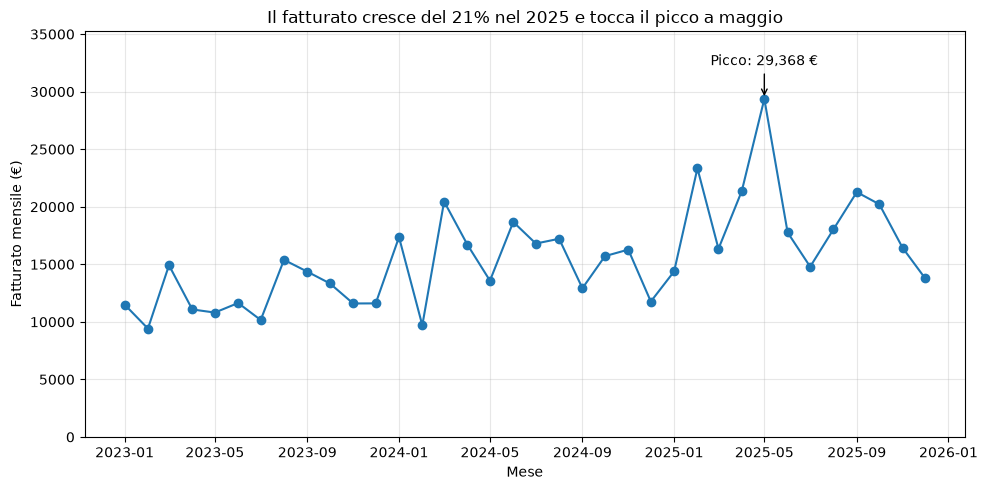

In [18]:
import matplotlib.pyplot as plt

fatturato_mensile["Periodo"] = pd.to_datetime(
    {"year": fatturato_mensile["Anno"], "month": fatturato_mensile["Mese"], "day": 1}
)

fatt_annuo = fatturato_mensile.groupby("Anno")["Fatturato"].sum()
crescita_2025 = (fatt_annuo[2025] / fatt_annuo[2024] - 1) * 100

riga_max = fatturato_mensile.loc[fatturato_mensile["Fatturato"].idxmax()]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(fatturato_mensile["Periodo"], fatturato_mensile["Fatturato"], marker="o")
ax.set_title(f"Il fatturato cresce del {crescita_2025:.0f}% nel 2025 e tocca il picco a maggio")
ax.set_xlabel("Mese")
ax.set_ylabel("Fatturato mensile (€)")
ax.set_ylim(0, riga_max["Fatturato"] * 1.2)
ax.annotate(f"Picco: {riga_max['Fatturato']:,.0f} €",
            xy=(riga_max["Periodo"], riga_max["Fatturato"]),
            xytext=(riga_max["Periodo"], riga_max["Fatturato"] * 1.1),
            ha="center", arrowprops=dict(arrowstyle="->"))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Domanda di business:** come si è mosso il fatturato nei tre anni e quando ha raggiunto il massimo?
**Risposta:** il fatturato mensile cresce nel tempo, con un aumento del 21% nel 2025 rispetto al 2024, e raggiunge il picco a maggio 2025 con circa 29.368 €.

## Task 4 - Punto 2: boxplot per categoria e heatmap dei rivenditori
Con Seaborn confronto la distribuzione degli importi di vendita tra le categorie (boxplot) e le relazioni tra le variabili numeriche dei rivenditori (heatmap di correlazione).

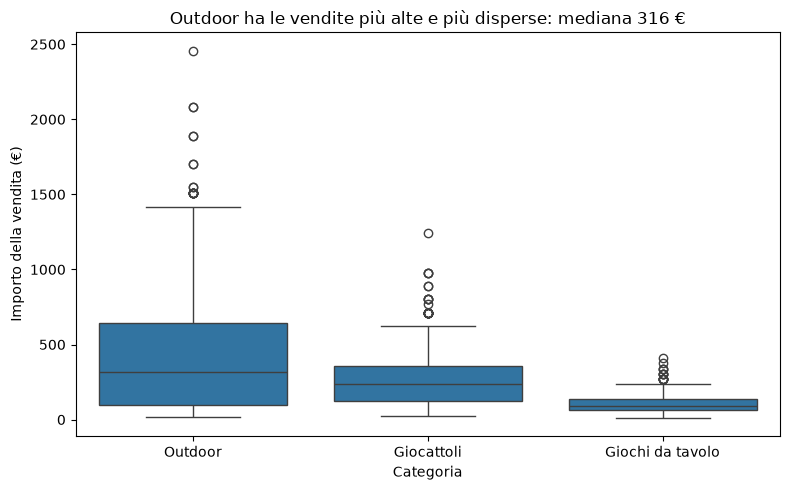

In [19]:
import seaborn as sns

mediane = df_full.groupby("Category")["SalesAmount"].median()
cat_top = mediane.idxmax()

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df_full, x="Category", y="SalesAmount",
            order=mediane.sort_values(ascending=False).index, ax=ax)
ax.set_title(f"{cat_top} ha le vendite più alte e più disperse: mediana {mediane[cat_top]:.0f} €")
ax.set_xlabel("Categoria")
ax.set_ylabel("Importo della vendita (€)")
plt.tight_layout()
plt.show()

**Domanda di business:** quale categoria genera le vendite singole più alte e più variabili?
**Risposta:** Outdoor ha la mediana più alta (316 €) e la scatola più larga, con vendite anomale oltre i 2.400 €, mentre i Giochi da tavolo sono piccoli e concentrati (mediana circa 90 €).

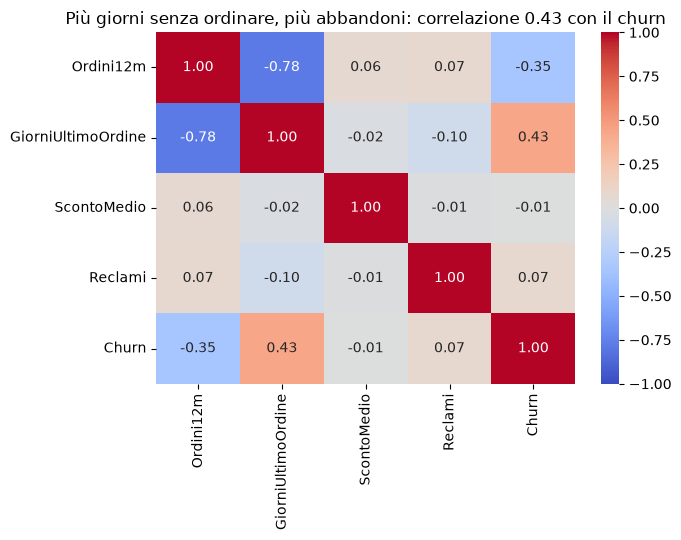

In [20]:
variabili = ["Ordini12m", "GiorniUltimoOrdine", "ScontoMedio", "Reclami", "Churn"]
corr = df_resellers[variabili].corr()
r = corr.loc["GiorniUltimoOrdine", "Churn"]

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title(f"Più giorni senza ordinare, più abbandoni: correlazione {r:.2f} con il churn")
plt.tight_layout()
plt.show()

**Domanda di business:** quali caratteristiche dei rivenditori sono legate all'abbandono?
**Risposta:** il churn cresce con i giorni dall'ultimo ordine (0,43) e diminuisce con il numero di ordini (-0,35), mentre sconto e reclami hanno un legame quasi nullo.

## Task 4 - Punto 3: fatturato per stato con Plotly
Grafico a barre interattivo del fatturato per stato: passando il mouse su ogni barra compaiono quantità totale e numero di transazioni.


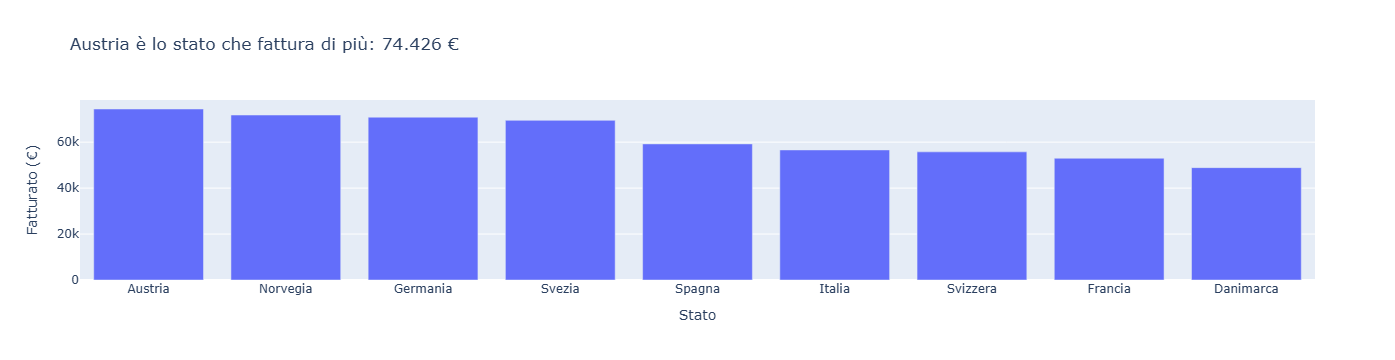

In [21]:
import plotly.express as px

per_stato = (
    df_full.groupby("State")
    .agg(Fatturato=("SalesAmount", "sum"),
         Quantita=("Quantity", "sum"),
         Transazioni=("SalesID", "count"))
    .sort_values("Fatturato", ascending=False)
    .reset_index()
)

top = per_stato.iloc[0]
fatturato_top = f"{top['Fatturato']:,.0f}".replace(",", ".")

fig = px.bar(
    per_stato, x="State", y="Fatturato",
    hover_data={"State": False, "Fatturato": ":,.0f", "Quantita": ":,.0f", "Transazioni": True},
    labels={"State": "Stato", "Fatturato": "Fatturato (€)",
            "Quantita": "Quantità totale", "Transazioni": "N. transazioni"},
    title=f"{top['State']} è lo stato che fattura di più: {fatturato_top} €",
)
fig.show()

**Domanda di business:** quale stato porta più fatturato?
**Risposta:** l'Austria è prima con circa 74.400 € (278 transazioni), ma i primi quattro stati sono molto vicini tra loro, e la Danimarca chiude la classifica con circa 48.900 €.

### Definizione: come si sceglie il tipo di grafico

La scelta dipende dalla domanda e dal tipo di dato.

- **Andamento nel tempo → linee.** Collegano i punti in ordine cronologico e mostrano la direzione (usato per il fatturato mensile).
- **Confronto tra categorie → barre.** L'altezza permette di confrontare i valori di gruppi distinti (usato per il fatturato per stato).
- **Distribuzione → boxplot.** Mostra mediana, dispersione e valori anomali di una variabile (usato per gli importi per categoria).
- **Relazione tra variabili → heatmap o scatter.** La heatmap riassume le correlazioni tra molte variabili, lo scatter mostra la relazione tra due variabili.

## TASK 5 CORRELAZIONE E REGRESSIONE LINEARE

## Task 5 - Punto 1: tabella mensile e correlazioni
Costruisco una tabella con una riga per mese (fatturato, quantità, rivenditori attivi, indice del mese) e calcolo con .corr() la correlazione tra le tre misure.
La coppia più correlata è Fatturato e Quantità (0,868), se si vendono più pezzi, il fatturato sale quasi sempre.

In [22]:
dati_mensili = (
    df_full.groupby(["Anno", "Mese"], as_index=False)
    .agg(Fatturato=("SalesAmount", "sum"),
         Quantita=("Quantity", "sum"),
         Rivenditori=("ResellerID", "nunique"))
)
dati_mensili["IndiceMese"] = range(1, len(dati_mensili) + 1)

display(dati_mensili.head())

corr_mensile = dati_mensili[["Fatturato", "Quantita", "Rivenditori"]].corr().round(3)
display(corr_mensile)

,Anno,Mese,Fatturato,Quantita,Rivenditori,IndiceMese
0,2023,1,11499.8,214.0,51,1
1,2023,2,9414.9,171.0,43,2
2,2023,3,14917.2,223.0,48,3
3,2023,4,11077.9,220.0,51,4
4,2023,5,10806.7,188.0,49,5


,Fatturato,Quantita,Rivenditori
Fatturato,1.000,0.868,0.556
Quantita,0.868,1.000,0.673
Rivenditori,0.556,0.673,1.000


## Task 5 - Punti 2 e 3: regressione semplice e multipla
Divido i 36 mesi in train (28) e test (8) con train_test_split(test_size=0.2, random_state=42). Addestro due modelli con LinearRegression, uno semplice (fatturato su indice del mese) e uno multiplo (indice del mese, quantità, rivenditori attivi), e confronto coefficienti e R².

| Modello | Coefficienti | Intercetta | R² train | R² test |
|---|---|---|---|---|
| Semplice | indice mese: 303,58 | 10.602,53 | 0,477 | -1,879 |
| Multiplo | indice mese: -78,11; quantità: 85,31; rivenditori: -229,36 | 6.323,67 | 0,836 | -0,415 |

**Lettura dei risultati:** nel modello semplice il coefficiente dell'indice del mese vale 303,58, cioè il fatturato cresce in media di circa 304 € al mese. Sui dati di addestramento il modello multiplo spiega molto di più (R² 0,836 contro 0,477), ma sul test entrambi hanno un R² negativo, quindi non prevedono meglio della semplice media. Con soli 36 mesi, di cui 8 per il test, e con forti oscillazioni da un mese all'altro, una retta non basta a prevedere bene.

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = dati_mensili[["IndiceMese", "Quantita", "Rivenditori"]]
y = dati_mensili["Fatturato"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Mesi di train:", len(X_train), "- mesi di test:", len(X_test))

# Modello semplice: solo indice del mese
mod_semplice = LinearRegression().fit(X_train[["IndiceMese"]], y_train)

# Modello multiplo: indice del mese, quantità, rivenditori
mod_multiplo = LinearRegression().fit(X_train, y_train)

confronto_modelli = pd.DataFrame({
    "Modello": ["Semplice", "Multiplo"],
    "Coefficienti": [mod_semplice.coef_.round(2).tolist(), mod_multiplo.coef_.round(2).tolist()],
    "Intercetta": [round(mod_semplice.intercept_, 2), round(mod_multiplo.intercept_, 2)],
    "R² train": [round(mod_semplice.score(X_train[["IndiceMese"]], y_train), 3),
                 round(mod_multiplo.score(X_train, y_train), 3)],
    "R² test": [round(mod_semplice.score(X_test[["IndiceMese"]], y_test), 3),
                round(mod_multiplo.score(X_test, y_test), 3)],
})
display(confronto_modelli)

Mesi di train: 28 - mesi di test: 8


,Modello,Coefficienti,Intercetta,R² train,R² test
0,Semplice,[303.58],10602.53,0.477,-1.879
1,Multiplo,"[-78.11, 85.31, -229.36]",6323.67,0.836,-0.415


### Task 5 - Previsione dei tre mesi successivi (opzionale)
Con il modello semplice prevedo il fatturato dei tre mesi successivi all'ultimo disponibile (dicembre 2025): indici 37, 38 e 39.

| Mese | Fatturato previsto |
|---|---|
| Gennaio 2026 | 21.835 € |
| Febbraio 2026 | 22.138 € |
| Marzo 2026 | 22.442 € |

**Interpretazione del coefficiente:** il coefficiente dell'indice del mese vale 303,58, quindi il modello stima un aumento di circa 304 € di fatturato per ogni mese in più. Va però ricordato che l'R² sul test è negativo, quindi queste previsioni indicano solo la tendenza di fondo e non il valore preciso di ogni mese.

In [24]:
mesi_futuri = pd.DataFrame({"IndiceMese": [37, 38, 39]})
previsioni = mod_semplice.predict(mesi_futuri)

tabella_previsioni = pd.DataFrame({
    "Mese": ["Gennaio 2026", "Febbraio 2026", "Marzo 2026"],
    "IndiceMese": [37, 38, 39],
    "Fatturato previsto (€)": previsioni.round(0),
})
display(tabella_previsioni)

,Mese,IndiceMese,Fatturato previsto (€)
0,Gennaio 2026,37,21835.0
1,Febbraio 2026,38,22138.0
2,Marzo 2026,39,22442.0


### Definizione: R² (coefficiente di determinazione)

**Cos'è e cosa misura.** L'R² dice quanta parte della variabilità del fatturato è spiegata dal modello. Confronta gli errori del modello con quelli che si commetterebbero prevedendo sempre la media.

**Intervallo dei valori.** Va da 0 a 1: 1 significa previsioni perfette e 0 che il modello non fa meglio della media. Sui dati di test può diventare negativo, e in quel caso il modello prevede peggio della media (nel nostro caso -1,879 e -0,415).

**Perché non dimostra una causa.** Un R² alto o una correlazione alta dicono solo che due grandezze si muovono insieme, non che una provochi l'altra. Può esserci una terza causa comune, oppure un legame di semplice calcolo: fatturato e quantità sono correlati (0,868) perché il fatturato nasce da quantità per prezzo, e non perché le quantità "causino" qualcosa di misterioso. Inoltre due grandezze che crescono entrambe nel tempo risultano correlate anche se non c'entrano l'una con l'altra.

## TASK 6 CLASIFICAZIONE DEL CHURN DEI RIVENDITORI

## Task 6a - Punto 1: preparo i dati
Ho preso le quattro caratteristiche dei rivenditori (ordini, giorni dall'ultimo ordine, sconto medio, reclami) e le ho separate dalla colonna Churn, che è quella che voglio prevedere. Ho diviso i 300 rivenditori in 240 per addestrare il modello e 60 per verificarlo, facendo in modo che in entrambi i gruppi la quota di chi abbandona restasse simile (circa 24% e 23%). Poi ho messo le variabili sulla stessa scala, calcolandola solo sui dati di addestramento, così il test non influenza il modello in anticipo.

In [25]:
from sklearn.preprocessing import StandardScaler

X_ch = df_resellers[["Ordini12m", "GiorniUltimoOrdine", "ScontoMedio", "Reclami"]]
y_ch = df_resellers["Churn"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_ch, y_ch, test_size=0.2, random_state=42, stratify=y_ch
)
print("Rivenditori di train:", len(Xc_train), "- di test:", len(Xc_test))
print("Quota di abbandoni in train:", round(yc_train.mean(), 3), "- in test:", round(yc_test.mean(), 3))

scaler = StandardScaler().fit(Xc_train)
Xc_train_s = scaler.transform(Xc_train)
Xc_test_s = scaler.transform(Xc_test)

Rivenditori di train: 240 - di test: 60
Quota di abbandoni in train: 0.238 - in test: 0.233


## Task 6a - Punto 2: addestro il modello e guardo gli errori
Ho addestrato una regressione logistica, che per ogni rivenditore calcola la probabilità che abbandoni. Per decidere chi segnalare ho provato due soglie, 0,5 e 0,3, e per ognuna ho costruito la matrice di confusione.

| | Previsto: resta | Previsto: abbandona |
|---|---|---|
| **Soglia 0,5** · realtà: resta | 42 | 4 |
| **Soglia 0,5** · realtà: abbandona | 10 | 4 |
| **Soglia 0,3** · realtà: resta | 36 | 10 |
| **Soglia 0,3** · realtà: abbandona | 4 | 10 |

Con la soglia 0,5 il modello individua solo 4 rivenditori su 14 che abbandonano davvero. Abbassando la soglia a 0,3 ne individua 10 su 14, al prezzo di qualche falso allarme in più (10 invece di 4).

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

modello_churn = LogisticRegression().fit(Xc_train_s, yc_train)

proba_test = modello_churn.predict_proba(Xc_test_s)[:, 1]
pred_05 = modello_churn.predict(Xc_test_s)
pred_03 = (proba_test >= 0.3).astype(int)

print("Matrice di confusione, soglia 0,5:")
print(confusion_matrix(yc_test, pred_05))
print("Matrice di confusione, soglia 0,3:")
print(confusion_matrix(yc_test, pred_03))

Matrice di confusione, soglia 0,5:
[[42  4]
 [10  4]]
Matrice di confusione, soglia 0,3:
[[36 10]
 [ 4 10]]


## Task 6a - Punto 3: quanto è bravo il modello
Per ognuna delle due soglie ho calcolato tre misure: l'accuracy (quante previsioni sono giuste in tutto), la precision (tra quelli che segnalo a rischio, quanti abbandonano davvero) e la recall (tra quelli che abbandonano davvero, quanti riesco a individuare).

| Soglia | Accuracy | Precision | Recall |
|---|---|---|---|
| 0,5 | 0,767 | 0,500 | 0,286 |
| 0,3 | 0,767 | 0,500 | 0,714 |

Come confronto ho usato una baseline: prevedere che nessun rivenditore abbandoni. Così si ha ragione il 76,7% delle volte, quindi l'accuracy del modello è identica alla baseline e da sola non dice quasi niente. La differenza si vede nella recall: con la soglia 0,3 individuo circa 7 abbandoni su 10, con la 0,5 meno di 3.

**Soglia scelta: 0,3.** Perdere un rivenditore che sta per abbandonare costa più di fare un controllo in più su uno che sarebbe rimasto. A parità di accuracy preferisco quindi la soglia con la recall più alta, anche se genera qualche falso allarme in più.

In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

metriche = pd.DataFrame({
    "Soglia": [0.5, 0.3],
    "Accuracy": [accuracy_score(yc_test, pred_05), accuracy_score(yc_test, pred_03)],
    "Precision": [precision_score(yc_test, pred_05), precision_score(yc_test, pred_03)],
    "Recall": [recall_score(yc_test, pred_05), recall_score(yc_test, pred_03)],
}).round(3)
display(metriche)

baseline = (yc_test == 0).mean()
print("Accuracy della baseline (Churn = 0 per tutti):", round(baseline, 3))

,Soglia,Accuracy,Precision,Recall
0,0.5,0.767,0.5,0.286
1,0.3,0.767,0.5,0.714


Accuracy della baseline (Churn = 0 per tutti): 0.767


## Task 6a - Punto 4: il modello impara bene o no?
Ho confrontato i risultati sui dati di addestramento e su quelli di test, per capire se il modello "impara a memoria" (overfitting) oppure è troppo semplice (underfitting).

| Soglia | Accuracy train | Accuracy test | Recall train | Recall test |
|---|---|---|---|---|
| 0,5 | 0,775 | 0,767 | 0,316 | 0,286 |
| 0,3 | 0,742 | 0,767 | 0,754 | 0,714 |

I valori sono molto simili tra train e test, quindi non vedo overfitting: il modello va più o meno allo stesso modo sui dati già visti e su quelli nuovi. Lo considero un **buon adattamento**, anche se non eccezionale: l'AUC sul test è 0,761. Il test ha solo 60 rivenditori e 14 di loro abbandonano, quindi con pochi casi in più o in meno i numeri potrebbero muoversi di qualche punto.

In [28]:
from sklearn.metrics import roc_auc_score

proba_train = modello_churn.predict_proba(Xc_train_s)[:, 1]
pred_train_05 = modello_churn.predict(Xc_train_s)
pred_train_03 = (proba_train >= 0.3).astype(int)

confronto_train_test = pd.DataFrame({
    "Soglia": [0.5, 0.3],
    "Accuracy train": [accuracy_score(yc_train, pred_train_05), accuracy_score(yc_train, pred_train_03)],
    "Accuracy test": [accuracy_score(yc_test, pred_05), accuracy_score(yc_test, pred_03)],
    "Recall train": [recall_score(yc_train, pred_train_05), recall_score(yc_train, pred_train_03)],
    "Recall test": [recall_score(yc_test, pred_05), recall_score(yc_test, pred_03)],
}).round(3)
display(confronto_train_test)

print("AUC sul test:", round(roc_auc_score(yc_test, proba_test), 3))

,Soglia,Accuracy train,Accuracy test,Recall train,Recall test
0,0.5,0.775,0.767,0.316,0.286
1,0.3,0.742,0.767,0.754,0.714


AUC sul test: 0.761


### Definizione: apprendimento supervisionato e non supervisionato

**Supervisionato.** Il modello impara da esempi in cui la risposta giusta è già nota. Servono quindi dati con le caratteristiche (X) e anche la colonna da prevedere (y), e l'obiettivo è prevedere quella risposta per casi nuovi. Esempio dal nostro scenario: la regressione logistica che prevede il Churn dei rivenditori, perché nei dati sappiamo già chi ha abbandonato.

**Non supervisionato.** Qui non c'è nessuna risposta già nota: servono solo le caratteristiche, e l'obiettivo è scoprire una struttura nascosta, per esempio dei gruppi. Esempio dal nostro scenario: il K-Means del prossimo task, che divide i rivenditori in segmenti simili senza sapere in anticipo a quale gruppo appartengano.

## Task 6b - Punto 1: preparo i dati per formare i gruppi
Per dividere i rivenditori in gruppi simili mi servono tre informazioni su ciascuno: quanti ordini ha fatto, da quanti giorni non ordina e quanto fatturato ha portato. Il fatturato non c'è nel file dei rivenditori, quindi l'ho calcolato sommando le loro vendite (quelle già pulite). Quattro rivenditori su 300 non hanno nessuna vendita, e ho messo il loro fatturato a 0. Poi ho messo le tre variabili sulla stessa scala e ho calcolato l'inerzia per ogni numero di gruppi (k) da 1 a 10. L'inerzia misura quanto sono "larghi" i gruppi: più è bassa, più i rivenditori di uno stesso gruppo si somigliano.

L'inerzia scende da 900 con un solo gruppo a 137 con dieci gruppi: i primi passi migliorano molto, poi sempre meno.

In [29]:
import warnings
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")
from sklearn.cluster import KMeans

fatturato_riv = (
    df_full.groupby("ResellerID", as_index=False)["SalesAmount"].sum()
    .rename(columns={"SalesAmount": "FatturatoTotale"})
)

segmenti = pd.merge(df_resellers, fatturato_riv, on="ResellerID", how="left")
print("Rivenditori senza vendite:", segmenti["FatturatoTotale"].isna().sum())
segmenti["FatturatoTotale"] = segmenti["FatturatoTotale"].fillna(0)

colonne_km = ["Ordini12m", "GiorniUltimoOrdine", "FatturatoTotale"]
X_km = StandardScaler().fit_transform(segmenti[colonne_km])

inertie = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_km)
    inertie.append(km.inertia_)

tabella_inerzia = pd.DataFrame({"k": range(1, 11), "Inerzia": [round(i, 1) for i in inertie]})
display(tabella_inerzia)

Rivenditori senza vendite: 4


,k,Inerzia
0,1,900.0
1,2,433.7
2,3,319.2
3,4,257.2
4,5,225.6
5,6,198.6
6,7,180.7
7,8,164.8
8,9,149.7
9,10,137.0


## Task 6b - Punto 2: scelgo il numero di gruppi
Ho disegnato come cambia l'inerzia al crescere del numero di gruppi. All'inizio scende molto, da 900 a 434 passando da 1 a 2 gruppi, poi sempre più piano. Il gomito si vede a 3 gruppi: oltre quel punto ogni gruppo in più migliora poco la situazione e rende i risultati più difficili da leggere. Ho quindi scelto k = 3 e ho assegnato ogni rivenditore al suo gruppo, in una nuova colonna chiamata Cluster.

I tre gruppi hanno 95, 137 e 68 rivenditori.

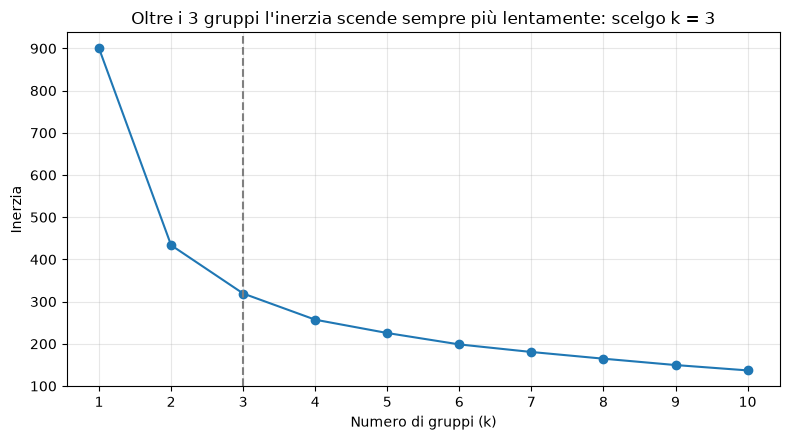

Rivenditori per gruppo:
Cluster
0     95
1    137
2     68
Name: count, dtype: int64


In [30]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, 11), inertie, marker="o")
ax.axvline(3, linestyle="--", color="gray")
ax.set_title("Oltre i 3 gruppi l'inerzia scende sempre più lentamente: scelgo k = 3")
ax.set_xlabel("Numero di gruppi (k)")
ax.set_ylabel("Inerzia")
ax.set_xticks(range(1, 11))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

k_scelto = 3
km_finale = KMeans(n_clusters=k_scelto, n_init=10, random_state=42)
segmenti["Cluster"] = km_finale.fit_predict(X_km)

print("Rivenditori per gruppo:")
print(segmenti["Cluster"].value_counts().sort_index())

## Task 6b - Punto 3: chi sono i tre gruppi
Per capire chi sono i gruppi ho guardato le medie di ordini, giorni dall'ultimo ordine, fatturato, sconto e reclami, e solo alla fine ho aggiunto la quota di rivenditori che hanno abbandonato (il modello non l'ha mai usata per formare i gruppi). Ho dato un nome a ciascuno in base a come si comporta.

| Segmento | Rivenditori | Ordini in 12 mesi | Giorni dall'ultimo ordine | Fatturato medio | Churn |
|---|---|---|---|---|---|
| Attivi di alto valore | 68 | 21,7 | 45,9 | 3.524 € | 10,3% |
| Attivi regolari | 95 | 19,6 | 48,3 | 1.515 € | 10,5% |
| In allontanamento | 137 | 12,4 | 141,5 | 1.288 € | 39,4% |

Sconto medio e reclami sono praticamente uguali nei tre gruppi, quindi non spiegano la differenza.

**Il segmento con il churn più alto è "In allontanamento": il 39,4% dei suoi rivenditori ha abbandonato.** Sono 54 abbandoni su 71 in totale, cioè circa tre su quattro. Sono rivenditori che ordinano poco e da molto tempo non ordinano: è qui che conviene concentrare le azioni di recupero.

In [31]:
profili = segmenti.groupby("Cluster").agg(
    Rivenditori=("ResellerID", "count"),
    Ordini12m=("Ordini12m", "mean"),
    GiorniUltimoOrdine=("GiorniUltimoOrdine", "mean"),
    FatturatoTotale=("FatturatoTotale", "mean"),
    ScontoMedio=("ScontoMedio", "mean"),
    Reclami=("Reclami", "mean"),
    Abbandoni=("Churn", "sum"),
).round(2)

profili["Churn (%)"] = (segmenti.groupby("Cluster")["Churn"].mean() * 100).round(1)

# Nomi assegnati in base alle caratteristiche di ogni gruppo
cluster_rischio = profili["GiorniUltimoOrdine"].idxmax()
cluster_top = profili.drop(cluster_rischio)["FatturatoTotale"].idxmax()

nomi = {}
for cl in profili.index:
    if cl == cluster_rischio:
        nomi[cl] = "In allontanamento"
    elif cl == cluster_top:
        nomi[cl] = "Attivi di alto valore"
    else:
        nomi[cl] = "Attivi regolari"

profili.insert(0, "Segmento", profili.index.map(nomi))
segmenti["Segmento"] = segmenti["Cluster"].map(nomi)

display(profili)


,Segmento,Rivenditori,Ordini12m,GiorniUltimoOrdine,FatturatoTotale,ScontoMedio,Reclami,Abbandoni,Churn (%)
Cluster,,,,,,,,,
0,Attivi regolari,95,19.58,48.35,1514.70,0.13,0.99,10,10.5
1,In allontanamento,137,12.42,141.48,1288.47,0.12,0.99,54,39.4
2,Attivi di alto valore,68,21.66,45.90,3524.38,0.13,1.03,7,10.3


### Definizione: centroide e inerzia, e perché K-Means non ha bisogno di y né di train e test

**Centroide.** È il "centro" di un gruppo: la media delle variabili di tutti i rivenditori che ne fanno parte. K-Means assegna ogni rivenditore al centroide più vicino, poi ricalcola i centroidi e ripete finché i gruppi non cambiano più.

**Inerzia.** È la somma dei quadrati delle distanze tra ogni rivenditore e il centroide del suo gruppo. Dice quanto i gruppi sono compatti: più è bassa, più i rivenditori di uno stesso gruppo si somigliano. Diminuisce sempre quando aumentano i gruppi, ed è per questo che si cerca il gomito invece del valore più basso.

**Perché non serve una colonna y.** K-Means è un apprendimento non supervisionato: non c'è una risposta giusta da imparare, usa solo le caratteristiche dei rivenditori per trovare somiglianze. Il Churn l'ho usato soltanto dopo, per leggere i gruppi.

**Perché non serve la divisione train e test.** Quella divisione serve a controllare quanto un modello prevede bene su dati mai visti, confrontando la previsione con una risposta nota. Qui non c'è nessuna previsione da verificare: il modello descrive i rivenditori che abbiamo, quindi si lavora su tutti.